# Predicting Fourth-Down Conversions in the NFL
CSCI 4380 Data Mining, University of Georgia — Senait Pirani

Compares logistic regression, random forest and LightGBM for predicting fourth-down success, then compares a simple expected-value recommendation to what coaches actually did.


## 1. Setup


In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier

## 2. Load data
Fourth-down plays from nflfastR play-by-play, 2016–2024 regular seasons.


In [25]:
df = pd.read_csv("../data/fourth_down_2016_2024.csv")
print(df.shape)
df.head()


(37489, 21)


,season,week,game_id,play_id,posteam,defteam,down,ydstogo,yardline_100,play_type,...,game_seconds_remaining,half_seconds_remaining,score_differential,epa,wp,home_team,away_team,roof,weather,first_down
0,2016,1,2016_01_BUF_BAL,175.0,BAL,BUF,4.0,1.0,66.0,no_play,...,3425.0,1625.0,0.0,-0.922621,0.510273,BAL,BUF,outdoors,"Partly Cloudy Temp: 84° F, Humidity: 44%, Wind...",0.0
1,2016,1,2016_01_BUF_BAL,198.0,BAL,BUF,4.0,6.0,71.0,punt,...,3412.0,1612.0,0.0,-0.405048,0.471003,BAL,BUF,outdoors,"Partly Cloudy Temp: 84° F, Humidity: 44%, Wind...",0.0
2,2016,1,2016_01_BUF_BAL,285.0,BUF,BAL,4.0,18.0,76.0,punt,...,3282.0,1482.0,0.0,0.224181,0.418961,BAL,BUF,outdoors,"Partly Cloudy Temp: 84° F, Humidity: 44%, Wind...",0.0
3,2016,1,2016_01_BUF_BAL,543.0,BUF,BAL,4.0,6.0,43.0,no_play,...,3030.0,1230.0,0.0,-0.440463,0.474963,BAL,BUF,outdoors,"Partly Cloudy Temp: 84° F, Humidity: 44%, Wind...",0.0
4,2016,1,2016_01_BUF_BAL,570.0,BUF,BAL,4.0,11.0,48.0,punt,...,3030.0,1230.0,0.0,0.447958,0.475927,BAL,BUF,outdoors,"Partly Cloudy Temp: 84° F, Humidity: 44%, Wind...",0.0


## 3. Clean


In [27]:
# keep only 4th downs (safety)
df = df[df["down"] == 4].copy()

# remove weird / impossible rows
df = df[df["ydstogo"] > 0]
df = df[df["yardline_100"].between(0, 100)]

print(df.shape)
df.head()


(37489, 21)


,season,week,game_id,play_id,posteam,defteam,down,ydstogo,yardline_100,play_type,...,game_seconds_remaining,half_seconds_remaining,score_differential,epa,wp,home_team,away_team,roof,weather,first_down
0,2016,1,2016_01_BUF_BAL,175.0,BAL,BUF,4.0,1.0,66.0,no_play,...,3425.0,1625.0,0.0,-0.922621,0.510273,BAL,BUF,outdoors,"Partly Cloudy Temp: 84° F, Humidity: 44%, Wind...",0.0
1,2016,1,2016_01_BUF_BAL,198.0,BAL,BUF,4.0,6.0,71.0,punt,...,3412.0,1612.0,0.0,-0.405048,0.471003,BAL,BUF,outdoors,"Partly Cloudy Temp: 84° F, Humidity: 44%, Wind...",0.0
2,2016,1,2016_01_BUF_BAL,285.0,BUF,BAL,4.0,18.0,76.0,punt,...,3282.0,1482.0,0.0,0.224181,0.418961,BAL,BUF,outdoors,"Partly Cloudy Temp: 84° F, Humidity: 44%, Wind...",0.0
3,2016,1,2016_01_BUF_BAL,543.0,BUF,BAL,4.0,6.0,43.0,no_play,...,3030.0,1230.0,0.0,-0.440463,0.474963,BAL,BUF,outdoors,"Partly Cloudy Temp: 84° F, Humidity: 44%, Wind...",0.0
4,2016,1,2016_01_BUF_BAL,570.0,BUF,BAL,4.0,11.0,48.0,punt,...,3030.0,1230.0,0.0,0.447958,0.475927,BAL,BUF,outdoors,"Partly Cloudy Temp: 84° F, Humidity: 44%, Wind...",0.0


## 4. Feature engineering


In [29]:
def engineer_features(df):
    # field position from offense POV
    df["yardline"] = 100 - df["yardline_100"]
    
    # score differential (offense minus defense already)
    df["score_diff"] = df["score_differential"]
    
    # log transform of yards to go
    df["log_ydstogo"] = np.log1p(df["ydstogo"])
    
    # time left in game (seconds)
    df["time_remaining"] = df["game_seconds_remaining"]
    
    # rolling offensive EPA per team
    df["off_epa_per_play"] = (
        df.groupby("posteam")["epa"]
          .transform(lambda x: x.rolling(50, min_periods=10).mean())
    )

    # rolling defensive EPA allowed
    df["def_epa_allowed"] = (
        df.groupby("defteam")["epa"]
          .transform(lambda x: x.rolling(50, min_periods=10).mean())
    )
    
    # did they go for it? (run or pass vs punt/etc.)
    df["actual_go_for_it"] = df["play_type"].isin(["run", "pass"]).astype(int)
    
    # did they convert?
    # some rows have NaN first_down; treat those as 0 (no first down)
    df["success"] = df["first_down"].fillna(0).astype(int)
    
    return df

df = engineer_features(df)
df.head()


,season,week,game_id,play_id,posteam,defteam,down,ydstogo,yardline_100,play_type,...,weather,first_down,yardline,score_diff,log_ydstogo,time_remaining,off_epa_per_play,def_epa_allowed,actual_go_for_it,success
0,2016,1,2016_01_BUF_BAL,175.0,BAL,BUF,4.0,1.0,66.0,no_play,...,"Partly Cloudy Temp: 84° F, Humidity: 44%, Wind...",0.0,34.0,0.0,0.693147,3425.0,NaN,NaN,0,0
1,2016,1,2016_01_BUF_BAL,198.0,BAL,BUF,4.0,6.0,71.0,punt,...,"Partly Cloudy Temp: 84° F, Humidity: 44%, Wind...",0.0,29.0,0.0,1.945910,3412.0,NaN,NaN,0,0
2,2016,1,2016_01_BUF_BAL,285.0,BUF,BAL,4.0,18.0,76.0,punt,...,"Partly Cloudy Temp: 84° F, Humidity: 44%, Wind...",0.0,24.0,0.0,2.944439,3282.0,NaN,NaN,0,0
3,2016,1,2016_01_BUF_BAL,543.0,BUF,BAL,4.0,6.0,43.0,no_play,...,"Partly Cloudy Temp: 84° F, Humidity: 44%, Wind...",0.0,57.0,0.0,1.945910,3030.0,NaN,NaN,0,0
4,2016,1,2016_01_BUF_BAL,570.0,BUF,BAL,4.0,11.0,48.0,punt,...,"Partly Cloudy Temp: 84° F, Humidity: 44%, Wind...",0.0,52.0,0.0,2.484907,3030.0,NaN,NaN,0,0


## 5. Modeling dataset and train/test split


In [31]:
features = [
    "yardline",
    "ydstogo",
    "log_ydstogo",
    "score_diff",
    "time_remaining",
    "off_epa_per_play",
    "def_epa_allowed"
]

# drop rows with missing feature / target values
df_model = df.dropna(subset=features + ["success"]).copy()

X = df_model[features]
y = df_model["success"]

print(X.shape, y.shape)


(37179, 7) (37179,)


In [33]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)


## 6. Models
### Logistic regression (baseline)


In [35]:
logreg = LogisticRegression(max_iter=500)
logreg.fit(X_train, y_train)

pred_lr = logreg.predict(X_test)
proba_lr = logreg.predict_proba(X_test)[:, 1]

print("=== Logistic Regression ===")
print("Accuracy:", accuracy_score(y_test, pred_lr))
print("ROC-AUC:", roc_auc_score(y_test, proba_lr))
print(classification_report(y_test, pred_lr))


=== Logistic Regression ===
Accuracy: 0.9062937062937063
ROC-AUC: 0.872523398154784
              precision    recall  f1-score   support

           0       0.92      0.99      0.95      8357
           1       0.61      0.20      0.30       938

    accuracy                           0.91      9295
   macro avg       0.76      0.59      0.63      9295
weighted avg       0.89      0.91      0.88      9295



### Random forest


In [37]:
rf = RandomForestClassifier(
    n_estimators=300,
    max_depth=12,
    random_state=42
)

rf.fit(X_train, y_train)

pred_rf = rf.predict(X_test)
proba_rf = rf.predict_proba(X_test)[:, 1]

print("=== Random Forest ===")
print("Accuracy:", accuracy_score(y_test, pred_rf))
print("ROC-AUC:", roc_auc_score(y_test, proba_rf))
print(classification_report(y_test, pred_rf))


=== Random Forest ===
Accuracy: 0.9114577729962345
ROC-AUC: 0.8984784278746442
              precision    recall  f1-score   support

           0       0.92      0.98      0.95      8357
           1       0.64      0.29      0.40       938

    accuracy                           0.91      9295
   macro avg       0.78      0.63      0.67      9295
weighted avg       0.90      0.91      0.90      9295



### LightGBM


In [38]:
lgb = LGBMClassifier(
    n_estimators=400,
    learning_rate=0.05,
    subsample=0.9,
    colsample_bytree=0.9,
    objective="binary",
    class_weight="balanced",
    random_state=42
)

lgb.fit(X_train, y_train)

pred_lgb = lgb.predict(X_test)
proba_lgb = lgb.predict_proba(X_test)[:, 1]

print("=== LightGBM ===")
print("Accuracy:", accuracy_score(y_test, pred_lgb))
print("ROC-AUC:", roc_auc_score(y_test, proba_lgb))
print(classification_report(y_test, pred_lgb))


[LightGBM] [Info] Number of positive: 2726, number of negative: 25158
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000661 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1034
[LightGBM] [Info] Number of data points in the train set: 27884, number of used features: 7
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Info] Start training from score 0.000000
=== LightGBM ===
Accuracy: 0.8560516406670253
ROC-AUC: 0.8986317663804941
              precision    recall  f1-score   support

           0       0.97      0.87      0.92      8357
           1       0.39      0.77      0.52       938

    accuracy                           0.86      9295
   macro avg       0.68      0.82      0.72      9295
weighted avg       0.91      0.86      0.88      9295



## 7. Model comparison


In [39]:
results = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest", "LightGBM"],
    "Accuracy": [
        accuracy_score(y_test, pred_lr),
        accuracy_score(y_test, pred_rf),
        accuracy_score(y_test, pred_lgb),
    ],
    "ROC_AUC": [
        roc_auc_score(y_test, proba_lr),
        roc_auc_score(y_test, proba_rf),
        roc_auc_score(y_test, proba_lgb),
    ]
})

results


,Model,Accuracy,ROC_AUC
0,Logistic Regression,0.906294,0.872523
1,Random Forest,0.911458,0.898478
2,LightGBM,0.856052,0.898632


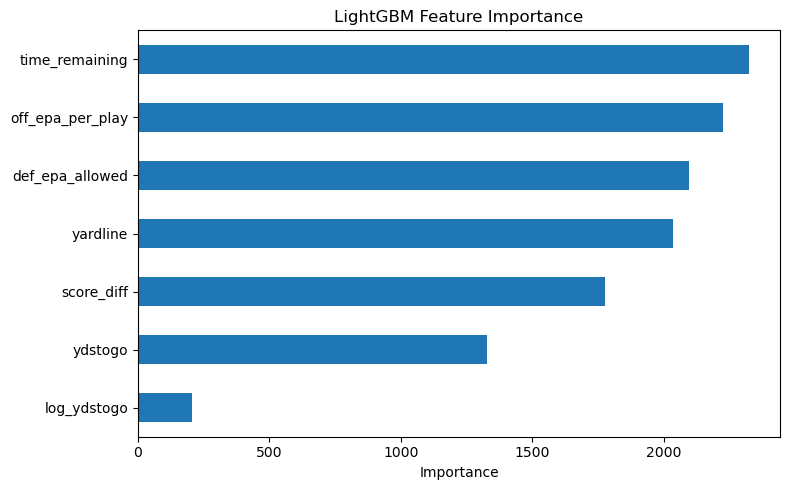

In [40]:
importances = pd.Series(
    lgb.feature_importances_, index=features
).sort_values(ascending=True)

plt.figure(figsize=(8,5))
importances.plot(kind="barh")
plt.title("LightGBM Feature Importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()


## 8. Go-for-it recommendation vs. actual coaching decisions


In [41]:
# Use LightGBM predicted success probability for every play
df_model["pred_success_prob"] = lgb.predict_proba(df_model[features])[:, 1]

# Expected EPA if they go for it (we approximate with actual EPA)
df_model["ev_go"] = df_model["pred_success_prob"] * df_model["epa"]

# Simple constant for punt EPA (you can tune this in your write-up)
punt_epa_estimate = -1.2
df_model["ev_punt"] = punt_epa_estimate

# Model recommendation: go if ev_go > ev_punt
df_model["recommend_go"] = (df_model["ev_go"] > df_model["ev_punt"]).astype(int)

df_model[["ev_go", "ev_punt", "recommend_go"]].head()


,ev_go,ev_punt,recommend_go
15,-0.117923,-1.2,1
18,0.000968,-1.2,1
76,-0.005657,-1.2,1
104,1.563358,-1.2,1
105,-2.065827,-1.2,0


In [49]:
agreement = np.mean(df_model["recommend_go"] == df_model["actual_go_for_it"])
print("Coach vs Model agreement rate:", agreement)


Coach vs Model agreement rate: 0.12509750127760294


## 9. ROC curves, calibration and confusion matrices


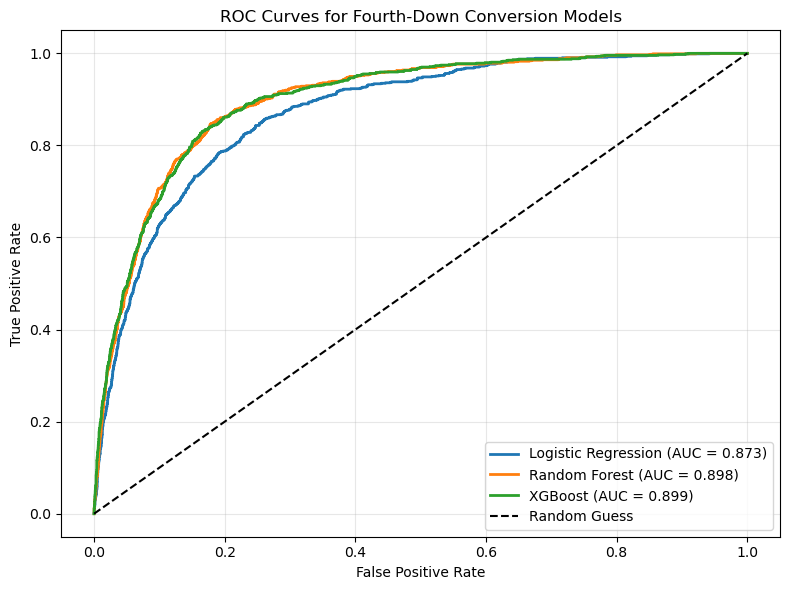

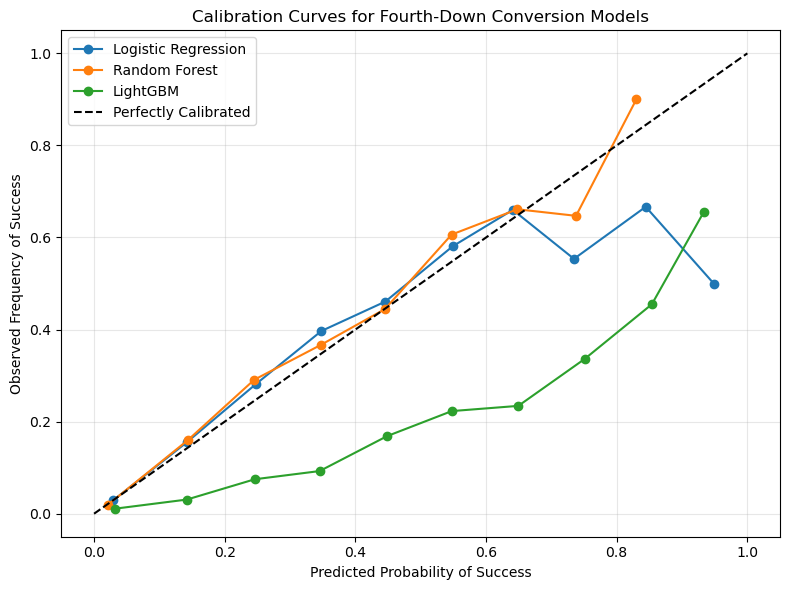

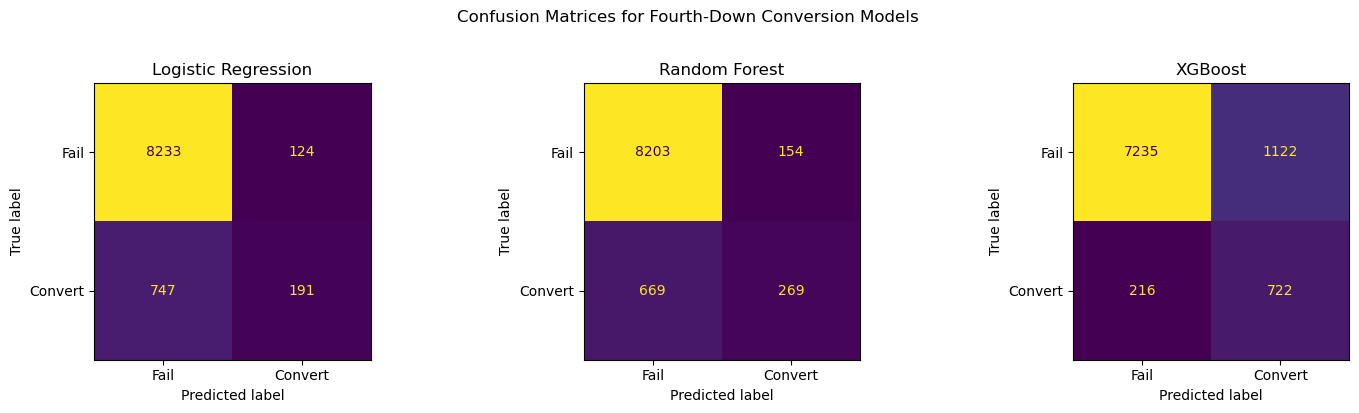

In [63]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (
    roc_curve,
    roc_auc_score,
    ConfusionMatrixDisplay,
)
from sklearn.calibration import calibration_curve

# ============ ROC CURVES ============

# ROC points
fpr_lr,  tpr_lr,  _ = roc_curve(y_test, proba_lr)
fpr_rf,  tpr_rf,  _ = roc_curve(y_test, proba_rf)
fpr_lgb, tpr_lgb, _ = roc_curve(y_test, proba_lgb)

# AUCs
auc_lr  = roc_auc_score(y_test, proba_lr)
auc_rf  = roc_auc_score(y_test, proba_rf)
auc_lgb = roc_auc_score(y_test, proba_lgb)

plt.figure(figsize=(8, 6))
plt.plot(fpr_lr,  tpr_lr,  label=f"Logistic Regression (AUC = {auc_lr:.3f})",  linewidth=2)
plt.plot(fpr_rf,  tpr_rf,  label=f"Random Forest (AUC = {auc_rf:.3f})",       linewidth=2)
plt.plot(fpr_lgb, tpr_lgb, label=f"XGBoost (AUC = {auc_lgb:.3f})",          linewidth=2)
plt.plot([0, 1], [0, 1], "k--", label="Random Guess")

plt.title("ROC Curves for Fourth-Down Conversion Models")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ============ CALIBRATION CURVES ============

plt.figure(figsize=(8, 6))

for name, proba in [
    ("Logistic Regression", proba_lr),
    ("Random Forest",       proba_rf),
    ("LightGBM",            proba_lgb),
]:
    frac_pos, mean_pred = calibration_curve(y_test, proba, n_bins=10, strategy="uniform")
    plt.plot(mean_pred, frac_pos, marker="o", linewidth=1.5, label=name)

plt.plot([0, 1], [0, 1], "k--", label="Perfectly Calibrated")

plt.title("Calibration Curves for Fourth-Down Conversion Models")
plt.xlabel("Predicted Probability of Success")
plt.ylabel("Observed Frequency of Success")
plt.legend(loc="upper left")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ============ CONFUSION MATRICES (optional) ============

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, y_pred, title in [
    (axes[0], pred_lr,  "Logistic Regression"),
    (axes[1], pred_rf,  "Random Forest"),
    (axes[2], pred_lgb, "XGBoost"),
]:
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        display_labels=["Fail", "Convert"],
        ax=ax,
        colorbar=False
    )
    ax.set_title(title)

fig.suptitle("Confusion Matrices for Fourth-Down Conversion Models", y=1.02)
plt.tight_layout()
plt.show()
